# Titanic: clasificación binaria con scikit-learn

Este notebook reproduce el ejemplo de clasificación binaria utilizado en la presentación. El objetivo es predecir si una persona sobrevivió al naufragio del Titanic a partir de algunas características disponibles.

La clase positiva es `Survived = 1`. Por lo tanto, un positivo significa que el modelo predice que la persona sobrevivió.

## 1. Cargar los datos

El archivo `titanic.csv` se encuentra en la carpeta `data`, un nivel por encima de este notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

data_path = Path('../data/titanic.csv')
df = pd.read_csv(data_path)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Preparar características y objetivo

Usaremos cuatro características numéricas o codificadas numéricamente. Eliminamos las filas sin edad disponible porque este ejemplo no introduce imputación de datos.

In [2]:
feature_cols = ['Pclass', 'Parch', 'Age', 'Sex']

df = df[feature_cols + ['Survived']].copy()
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df = df.dropna()

X = df[feature_cols]
y = df['Survived']

print(f'Observaciones disponibles: {len(df)}')
print(f'Clase positiva: {int(y.sum())}')
print(f'Clase negativa: {int((y == 0).sum())}')

Observaciones disponibles: 714
Clase positiva: 290
Clase negativa: 424


## 3. Separar entrenamiento y prueba

Se conserva `random_state=0` y `test_size=0.25` para reproducir los 179 casos de prueba utilizados en la slide. En un experimento real, la estrategia de partición debe considerar también grupos, tiempo y balance de clases cuando corresponda.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=0,
)

print(f'Entrenamiento: {len(y_train)} casos')
print(f'Prueba: {len(y_test)} casos')

Entrenamiento: 535 casos
Prueba: 179 casos


## 4. Ajustar el modelo

El `Pipeline` ajusta el escalador solo con entrenamiento y luego entrena una regresión logística. Así el preprocesamiento no utiliza información del conjunto de prueba.

In [4]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, 1]

## 5. Matriz de confusión

La matriz se organiza con las clases reales en las filas y las clases predichas en las columnas. El método `ravel` permite extraer `TN`, `FP`, `FN` y `TP` en ese orden.

Matriz de confusión:
[[87 16]
 [17 59]]
TN=87, FP=16, FN=17, TP=59


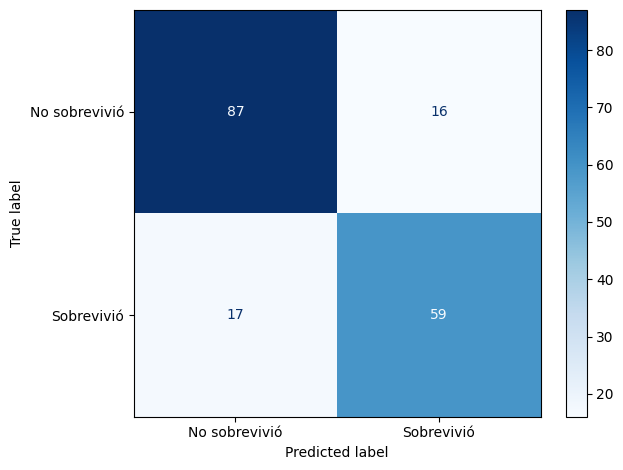

In [5]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print('Matriz de confusión:')
print(cm)
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No sobrevivió', 'Sobrevivió'],
).plot(cmap='Blues')
plt.tight_layout()
plt.show()

## 6. Calcular métricas

Las métricas se calculan a partir de los conteos de la matriz de confusión. ROC AUC utiliza el puntaje continuo producido por el modelo, no solo la etiqueta final.

In [6]:
specificity = tn / (tn + fp)

results = {
    'Exactitud': accuracy_score(y_test, y_pred),
    'Precisión': precision_score(y_test, y_pred),
    'Exhaustividad': recall_score(y_test, y_pred),
    'Especificidad': specificity,
    'F1': f1_score(y_test, y_pred),
    'ROC AUC': roc_auc_score(y_test, y_score),
}

pd.Series(results).round(4)

Exactitud        0.8156
Precisión        0.7867
Exhaustividad    0.7763
Especificidad    0.8447
F1               0.7815
ROC AUC          0.8524
dtype: float64

## 7. Relación con la slide

En este experimento, la matriz contiene `TN=87`, `FP=16`, `FN=17` y `TP=59`. Por lo tanto, la exactitud es `(87 + 59) / 179 = 81,6 %`. Las demás métricas ponderan estos mismos conteos de manera diferente.